# 04 · Explainability by persona category

Every live prediction comes with its top reasons. Tree models use **native, exact SHAP contributions** (no `shap` library needed in production).

In [1]:
%matplotlib inline
import warnings, os
warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from churnpulse import config
from churnpulse.dataset import load_customers
from churnpulse.features import FEATURE_CATEGORY, CATEGORIES
sns.set_theme(style="whitegrid", palette=["#0aa38a", "#f43f5e", "#f59e0b", "#6366f1", "#38bdf8"])
CAT_COLORS = {"geographic": "#38bdf8", "demographic": "#a78bfa", "technographic": "#22d3ee",
              "behavioural": "#fbbf24", "psychographic": "#f472b6"}
pd.set_option("display.max_columns", 50)


In [2]:
import json
from churnpulse.predict import ChurnModel
from churnpulse.train import load_split
model = ChurnModel(); card = json.loads(config.MODEL_CARD_PATH.read_text()); split = load_split()
{k: (m.model_name, round(card['models'][k]['test_metrics']['roc_auc'], 4)) for k, m in model.models.items()}

{'profile': ('lightgbm', 0.9166), 'survey': ('lightgbm', 0.9927)}

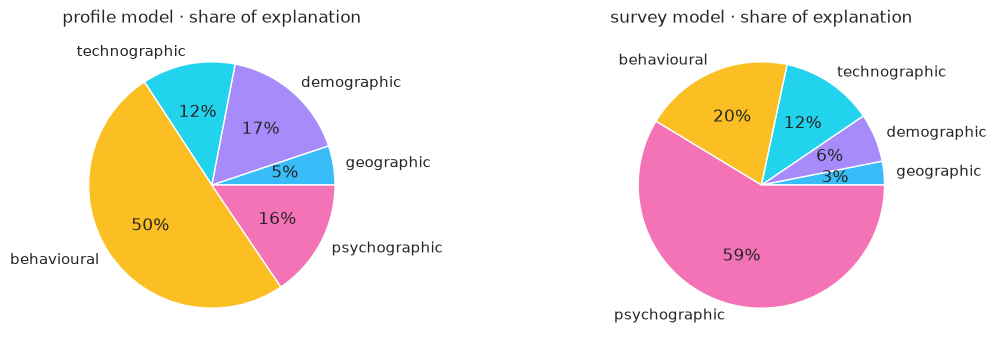

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kind in zip(axes, ['profile', 'survey']):
    s = pd.Series(card['models'][kind]['importance_by_category'])
    s.plot.pie(ax=ax, colors=[CAT_COLORS[c] for c in s.index], autopct='%1.0f%%', ylabel='')
    ax.set_title(f'{kind} model · share of explanation')
plt.show()

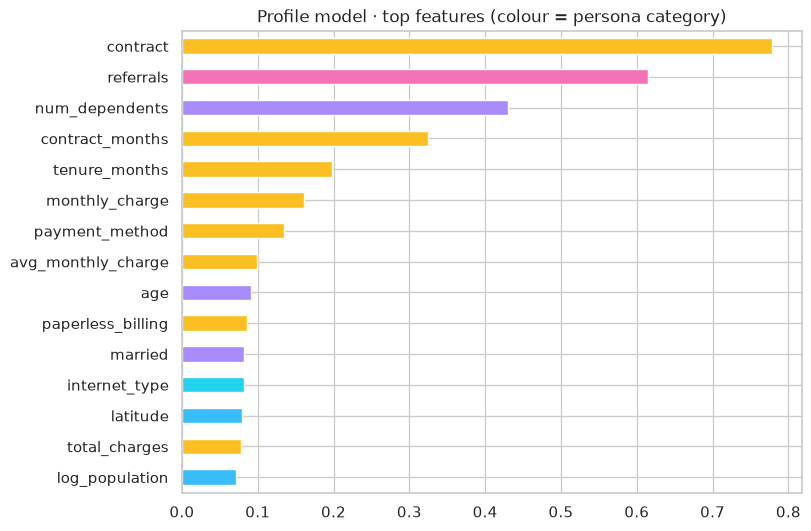

In [4]:
contrib = model.profile.explainer.contributions(split.X_test)
imp = contrib.abs().mean().sort_values().tail(15)
imp.plot.barh(color=[CAT_COLORS[FEATURE_CATEGORY[f]] for f in imp.index], figsize=(8, 6))
plt.title('Profile model · top features (colour = persona category)'); plt.show()

## Exactness check
Contributions + the base value must equal the model's raw score:

In [5]:
e = model.profile.explainer
Xt = e.prep.transform(split.X_test[model.profile.features].head(500))
full = e.model.predict(Xt, pred_contrib=True)
np.allclose(full.sum(axis=1), e.model.predict(Xt, raw_score=True))

True

## Explaining single customers

In [6]:
proba = model.profile.proba(split.X_test)
for label, idx in [('highest risk', proba.idxmax()), ('lowest risk', proba.idxmin())]:
    print(f'--- {label}: p={proba[idx]:.3f}, actually churned={split.y_test[idx]}')
    for r in model.profile.explainer.reasons(split.X_test.loc[[idx]]): print('   ', r)

--- highest risk: p=0.949, actually churned=1
    {'feature': 'referrals', 'category': 'psychographic', 'value': 1, 'impact': 0.9812, 'direction': 'raises risk'}
    {'feature': 'contract', 'category': 'behavioural', 'value': 'Month-to-Month', 'impact': 0.9709, 'direction': 'raises risk'}
    {'feature': 'latitude', 'category': 'geographic', 'value': 32.96, 'impact': 0.6987, 'direction': 'raises risk'}
    {'feature': 'num_dependents', 'category': 'demographic', 'value': 0, 'impact': 0.3966, 'direction': 'raises risk'}
    {'feature': 'contract_months', 'category': 'behavioural', 'value': 1, 'impact': 0.3898, 'direction': 'raises risk'}
--- lowest risk: p=0.041, actually churned=0
    {'feature': 'referrals', 'category': 'psychographic', 'value': 10, 'impact': -1.2375, 'direction': 'lowers risk'}
    {'feature': 'num_dependents', 'category': 'demographic', 'value': 3, 'impact': -0.7789, 'direction': 'lowers risk'}
    {'feature': 'contract', 'category': 'behavioural', 'value': 'Two Yea

## Retention actions for a risky customer
The action center re-scores counterfactuals with the same model:

In [7]:
from churnpulse.actions import recommend
from churnpulse.features import PROFILE_FIELDS
row = load_customers().set_index('customer_id').loc[split.ids_test.loc[proba.idxmax()]]
profile = {**row[PROFILE_FIELDS].to_dict(), 'satisfaction_score': None}
pd.DataFrame(recommend(model, profile, {'price_sensitivity': 5}, top=5))[['title', 'probability_before', 'probability_after', 'expected_value', 'why']]

,title,probability_before,probability_after,expected_value,why
0,Offer a 2-year contract,0.9493,0.3963,438.14,[]
1,Offer a 1-year contract,0.9493,0.8542,13.42,[price-sensitive customer]
